### Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# File path
file_path = r"C:\Users\user\OneDrive - Ariel University\שולחן העבודה\- (2).xlsx"

# Load Excel file
df = pd.read_excel(file_path)

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display first 5 rows
display(df.head())

Dataset shape: (1541, 34)


,זמן סיום מהמערכת,יישוב,סמל יישוב,שעת הגעה לנקודה,נ.צ כתובת,כתובת תיאור מיקום נקודת המדידה,סוג נקודת המדידה,בדלי סיגריות,קופסאות סיגריות,מסכות כירורגיות,...,פסולת אחרת למשל בגדים סוללות חומרי פרסום וכל מה שלא קוטלג בקבוצות האחרות,צואת כלבים,כתמי מסטיק,פריט פסולת גדול,אריזות קרטון,גרפיטי,אחר1,אחר2,בנקודת המדידה נאספו x שקיות של פרטי לכלוך,כמה אנשים עברו בנקודת המדידה בזמן התצפית
0,2021-09-27 11:05:26,שפרעם,8800,08:20:00,NaN,רחוב תלחמי ליד העירייה,מבנה ציבור,500,1,50,...,10,0,40,11,13,0,כסא משרדי ליד הכביש,משטח עץ ליד המדריכה,1.0,78
1,2021-09-27 12:45:41,שפרעם,8800,08:30:00,NaN,רח תופיק זיאד,רחוב מסחרי,128,15,41,...,1,2,23,2,3,1,אין,אין,1.0,42
2,2021-09-27 16:47:09,שפרעם,8800,12:30:00,"32.81329576547004,35.16374533931063",המעיין שפרעם,רחוב מסחרי,42,26,35,...,0,1,21,2,7,0,NaN,NaN,1.0,68
3,2021-09-27 17:00:57,שפרעם,8800,12:45:00,"32.8128593,35.1641509",רחוב אמין טריף,רחוב מגורים,200,22,24,...,1,2,7,3,3,0,NaN,NaN,1.0,16
4,2021-09-28 17:18:37,שפרעם,8800,13:00:00,"32.809298987119796,35.17813391737249",כביש חסן נמר שפרעם,רחוב מגורים,38,14,22,...,1,1,38,3,5,3,NaN,NaN,1.0,31


In [3]:
# 1. Dataset dimensions
print("========== DATASET SHAPE ==========")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# 2. Column names and data types
print("\n========== COLUMNS & DATA TYPES ==========")
print(df.dtypes.to_string())

# 3. First 5 rows
print("\n========== FIRST 5 ROWS ==========")
display(df.head())

# 4. General dataset information
print("\n========== DATASET INFO ==========")
df.info()

# 5. Numerical features summary
print("\n========== NUMERICAL SUMMARY ==========")
display(df.describe().T)

# 6. Categorical features summary
print("\n========== CATEGORICAL SUMMARY ==========")
display(df.describe(include=["object", "category"]).T)

========== DATASET SHAPE ==========
Rows: 1541
Columns: 34

========== COLUMNS & DATA TYPES ==========
זמן סיום מהמערכת                                                             datetime64[ns]
יישוב                                                                                object
סמל יישוב                                                                             int64
שעת הגעה לנקודה                                                                      object
נ.צ כתובת                                                                            object
כתובת תיאור מיקום נקודת המדידה                                                       object
סוג נקודת המדידה                                                                     object
בדלי סיגריות                                                                          int64
קופסאות סיגריות                                                                       int64
מסכות כירורגיות                                                      

,זמן סיום מהמערכת,יישוב,סמל יישוב,שעת הגעה לנקודה,נ.צ כתובת,כתובת תיאור מיקום נקודת המדידה,סוג נקודת המדידה,בדלי סיגריות,קופסאות סיגריות,מסכות כירורגיות,...,פסולת אחרת למשל בגדים סוללות חומרי פרסום וכל מה שלא קוטלג בקבוצות האחרות,צואת כלבים,כתמי מסטיק,פריט פסולת גדול,אריזות קרטון,גרפיטי,אחר1,אחר2,בנקודת המדידה נאספו x שקיות של פרטי לכלוך,כמה אנשים עברו בנקודת המדידה בזמן התצפית
0,2021-09-27 11:05:26,שפרעם,8800,08:20:00,NaN,רחוב תלחמי ליד העירייה,מבנה ציבור,500,1,50,...,10,0,40,11,13,0,כסא משרדי ליד הכביש,משטח עץ ליד המדריכה,1.0,78
1,2021-09-27 12:45:41,שפרעם,8800,08:30:00,NaN,רח תופיק זיאד,רחוב מסחרי,128,15,41,...,1,2,23,2,3,1,אין,אין,1.0,42
2,2021-09-27 16:47:09,שפרעם,8800,12:30:00,"32.81329576547004,35.16374533931063",המעיין שפרעם,רחוב מסחרי,42,26,35,...,0,1,21,2,7,0,NaN,NaN,1.0,68
3,2021-09-27 17:00:57,שפרעם,8800,12:45:00,"32.8128593,35.1641509",רחוב אמין טריף,רחוב מגורים,200,22,24,...,1,2,7,3,3,0,NaN,NaN,1.0,16
4,2021-09-28 17:18:37,שפרעם,8800,13:00:00,"32.809298987119796,35.17813391737249",כביש חסן נמר שפרעם,רחוב מגורים,38,14,22,...,1,1,38,3,5,3,NaN,NaN,1.0,31



========== DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1541 entries, 0 to 1540
Data columns (total 34 columns):
 #   Column                                                                     Non-Null Count  Dtype         
---  ------                                                                     --------------  -----         
 0   זמן סיום מהמערכת                                                           1541 non-null   datetime64[ns]
 1   יישוב                                                                      1541 non-null   object        
 2   סמל יישוב                                                                  1541 non-null   int64         
 3   שעת הגעה לנקודה                                                            1538 non-null   object        
 4   נ.צ כתובת                                                                  865 non-null    object        
 5   כתובת תיאור מיקום נקודת המדידה                                             

,count,mean,min,25%,50%,75%,max,std
זמן סיום מהמערכת,1541,2021-09-01 21:46:22.688513792,2021-07-04 00:00:00,2021-07-21 13:50:36,2021-08-25 12:15:53,2021-10-11 13:06:42,2021-11-25 22:54:31,NaN
סמל יישוב,1541.0,3147.077223,2.0,469.0,2630.0,6100.0,9600.0,3093.10495
בדלי סיגריות,1541.0,86.096042,0.0,9.0,30.0,80.0,1298.0,169.31613
קופסאות סיגריות,1541.0,10.167424,0.0,0.0,3.0,8.0,814.0,31.616768
מסכות כירורגיות,1541.0,12.123945,0.0,1.0,4.0,8.0,850.0,39.58546
מכלי משקה למיניהם,1541.0,13.724854,0.0,1.0,4.0,11.0,638.0,36.402042
פקקים של מכלי משקה,1541.0,23.510058,0.0,1.0,5.0,15.0,1167.0,78.608999
אריזות מזון Take Away נייר,1541.0,7.61843,0.0,0.0,1.0,5.0,726.0,29.659864
אריזות מזון Take Away פלסטיק,1541.0,5.282284,0.0,0.0,0.0,4.0,748.0,28.69719
צלחות חדפ,1541.0,4.343933,0.0,0.0,0.0,2.0,278.0,18.867441



========== CATEGORICAL SUMMARY ==========


,count,unique,top,freq
יישוב,1541,79,ירושלים,236
שעת הגעה לנקודה,1538,564,09:00:00,36
נ.צ כתובת,865,797,0,46
כתובת תיאור מיקום נקודת המדידה,1540,1474,מרכז מסחרי,13
סוג נקודת המדידה,1541,7,רחוב מגורים,590
אחר1,753,268,0,429
אחר2,623,116,0,473


### Missing values

In [5]:
summary = pd.DataFrame({
    'Column': df.columns,
    'Non-Null Values': df.notna().sum().values,
    'Missing Values': df.isna().sum().values,
    'Missing (%)': (df.isna().mean() * 100).round(2).values
})

display(summary)

,Column,Non-Null Values,Missing Values,Missing (%)
0,זמן סיום מהמערכת,1541,0,0.00
1,יישוב,1541,0,0.00
2,סמל יישוב,1541,0,0.00
3,שעת הגעה לנקודה,1538,3,0.19
4,נ.צ כתובת,865,676,43.87
5,כתובת תיאור מיקום נקודת המדידה,1540,1,0.06
6,סוג נקודת המדידה,1541,0,0.00
7,בדלי סיגריות,1541,0,0.00
8,קופסאות סיגריות,1541,0,0.00
9,מסכות כירורגיות,1541,0,0.00


### Outlier Detection

In [7]:
litter_columns = df.columns[7:30]

outliers_summary = []

for col in litter_columns:
    values = pd.to_numeric(df[col], errors="coerce")

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((values < lower_bound) | (values > upper_bound)).sum()

    outliers_summary.append({
        "Feature": col,
        "Min": values.min(),
        "Max": values.max(),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Outliers": outliers,
        "Outliers (%)": round(outliers / len(df) * 100, 2)
    })

outliers_df = pd.DataFrame(outliers_summary)

display(outliers_df.sort_values("Outliers", ascending=False))

,Feature,Min,Max,Q1,Q3,IQR,Outliers,Outliers (%)
22,גרפיטי,0.0,174.0,0.0,0.0,0.0,363,23.56
16,פסולת בלתי חוקית שקית אשפה מלאה שהושלכה ברחוב,0.0,260.0,0.0,1.0,1.0,257,16.68
15,פסולת אורגנית,0.0,200.0,0.0,1.0,1.0,252,16.35
2,מסכות כירורגיות,0.0,850.0,1.0,8.0,7.0,210,13.63
7,צלחות חדפ,0.0,278.0,0.0,2.0,2.0,206,13.37
4,פקקים של מכלי משקה,0.0,1167.0,1.0,15.0,14.0,202,13.11
20,פריט פסולת גדול,0.0,500.0,0.0,3.0,3.0,194,12.59
17,פסולת אחרת למשל בגדים סוללות חומרי פרסום וכל מ...,0.0,202.0,0.0,3.0,3.0,194,12.59
3,מכלי משקה למיניהם,0.0,638.0,1.0,11.0,10.0,189,12.26
21,אריזות קרטון,0.0,1254.0,0.0,5.0,5.0,187,12.13


### Check duplicate rows

In [9]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

# Display duplicated rows
display(df[df.duplicated(keep=False)])

Total rows: 1541
Duplicate rows: 7
Unique rows: 1534


,זמן סיום מהמערכת,יישוב,סמל יישוב,שעת הגעה לנקודה,נ.צ כתובת,כתובת תיאור מיקום נקודת המדידה,סוג נקודת המדידה,בדלי סיגריות,קופסאות סיגריות,מסכות כירורגיות,...,פסולת אחרת למשל בגדים סוללות חומרי פרסום וכל מה שלא קוטלג בקבוצות האחרות,צואת כלבים,כתמי מסטיק,פריט פסולת גדול,אריזות קרטון,גרפיטי,אחר1,אחר2,בנקודת המדידה נאספו x שקיות של פרטי לכלוך,כמה אנשים עברו בנקודת המדידה בזמן התצפית
323,2021-10-03 12:28:38,ירושלים,3000,12:00:00,"31.7796316,35.2180051",מול חניון מגדלי ירושלים,רחוב מגורים,70,3,8,...,3,0,32,7,5,0,0,0,9.0,134
326,2021-10-03 12:28:38,ירושלים,3000,12:00:00,"31.7796316,35.2180051",מול חניון מגדלי ירושלים,רחוב מגורים,70,3,8,...,3,0,32,7,5,0,0,0,9.0,134
491,2021-10-05 16:34:28,ירושלים,3000,15:40:00,NaN,ראס אלעמוד בית ספר בנים,מבנה ציבור,23,4,2,...,0,0,40,6,3,1,NaN,NaN,2.0,90
492,2021-10-05 16:57:10,ירושלים,3000,16:43:00,NaN,ארבעת בתי כנסת ספרדי,מבנה ציבור,8,4,3,...,1,0,1,0,3,0,NaN,NaN,0.0,200
493,2021-10-05 18:12:59,ירושלים,3000,17:40:00,NaN,ראס אלעמוד בית ספר בנות,מבנה ציבור,12,3,0,...,0,0,3,1,3,1,NaN,NaN,2.0,40
494,2021-10-06 11:22:43,ירושלים,3000,09:30:00,NaN,סילוואן - יסוד בנים,מבנה ציבור,0,0,0,...,0,0,0,0,0,0,NaN,NaN,0.0,100
495,2021-10-10 15:21:11,ירושלים,3000,13:25:00,NaN,מעון נכים,רחוב מגורים,57,4,2,...,0,3,8,1,1,0,NaN,NaN,1.0,100
496,2021-10-07 15:50:27,ירושלים,3000,14:13:00,"31.7891482,35.2070182",רחוב מלכי ישראל,רחוב מסחרי,16,2,6,...,5,0,0,1,5,0,NaN,NaN,6.0,721
543,2021-10-05 16:34:28,ירושלים,3000,15:40:00,NaN,ראס אלעמוד בית ספר בנים,מבנה ציבור,23,4,2,...,0,0,40,6,3,1,NaN,NaN,2.0,90
544,2021-10-05 16:57:10,ירושלים,3000,16:43:00,NaN,ארבעת בתי כנסת ספרדי,מבנה ציבור,8,4,3,...,1,0,1,0,3,0,NaN,NaN,0.0,200


,Class,Count,Percentage (%)
0,רחוב מגורים,590,38.29
1,רחוב מסחרי,244,15.83
2,פנאי ונופש,233,15.12
3,מבנה ציבור,227,14.73
4,מרכז מסחרי,130,8.44
5,אזור תעשייה,96,6.23
6,חוף ים,21,1.36


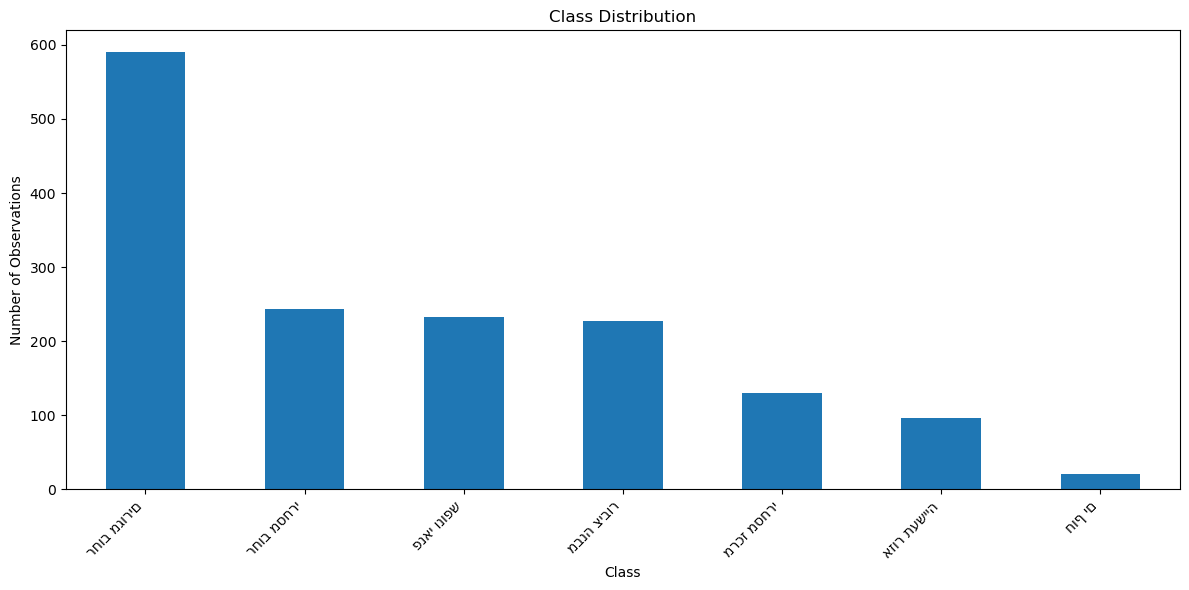

Number of classes: 7
Majority class: רחוב מגורים
Minority class: חוף ים
Imbalance ratio: 28.1


In [11]:
import matplotlib.pyplot as plt

# Target variable
target = "סוג נקודת המדידה"

# Class distribution
class_counts = df[target].value_counts()

class_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage (%)": (class_counts.values / len(df) * 100).round(2)
})

display(class_summary)

# Class distribution chart
plt.figure(figsize=(12, 6))

class_counts.plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Imbalance ratio
print("Number of classes:", len(class_counts))
print("Majority class:", class_counts.idxmax())
print("Minority class:", class_counts.idxmin())
print("Imbalance ratio:", round(class_counts.max() / class_counts.min(), 2))

In [ ]:
### התאמה קלסיפיקציה

In [13]:
target = "סוג נקודת המדידה"
litter_columns = df.columns[7:30].tolist()

# Prepare features and target
X = df[litter_columns].apply(pd.to_numeric, errors="coerce")
y = df[target]

# Remove rows with missing target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Median imputation for exploratory analysis
X = X.fillna(X.median()).fillna(0)

# 1. Kruskal-Wallis test
results = []

for col in litter_columns:
    groups = [
        X.loc[y == category, col].values
        for category in y.unique()
    ]

    if X[col].nunique() <= 1:
        p_value = np.nan
    else:
        _, p_value = kruskal(*groups)

    results.append({
        "Feature": col,
        "Kruskal p-value": p_value
    })

classification_results = pd.DataFrame(results)

# 2. Mutual Information
mi_scores = mutual_info_classif(
    X, y,
    discrete_features=True,
    random_state=42
)

classification_results["Mutual Information"] = mi_scores

# 3. Sort features by Mutual Information
classification_results = classification_results.sort_values(
    "Mutual Information",
    ascending=False
)

display(classification_results)

print(
    "Features with p-value < 0.05:",
    (classification_results["Kruskal p-value"] < 0.05).sum(),
    "out of",
    len(litter_columns)
)

,Feature,Kruskal p-value,Mutual Information
0,בדלי סיגריות,7.297436e-10,0.392020
19,כתמי מסטיק,1.571294e-15,0.282904
4,פקקים של מכלי משקה,6.105093e-01,0.216015
10,כוסות שתייה חמה חדפ,4.234362e-08,0.173043
14,פלסטיק אחר שקיות פלסטיק ורכיבי פלסטיק שאינם מכ...,1.640749e-02,0.171014
11,אריזות של חטיפים,1.405123e-03,0.168286
3,מכלי משקה למיניהם,1.626320e-02,0.167699
2,מסכות כירורגיות,8.927525e-08,0.162734
9,כוסות שתייה קרה חדפ,7.358077e-01,0.160206
13,נייר אחר לא אריזות מזון,7.484618e-02,0.157856


Features with p-value < 0.05: 17 out of 23


========== DATA VARIABILITY ==========
Observations: 1541
Features: 23
Unique feature combinations: 1519
Constant features: 0

========== PCA ==========
Explained variance by first 2 components: 50.89 %


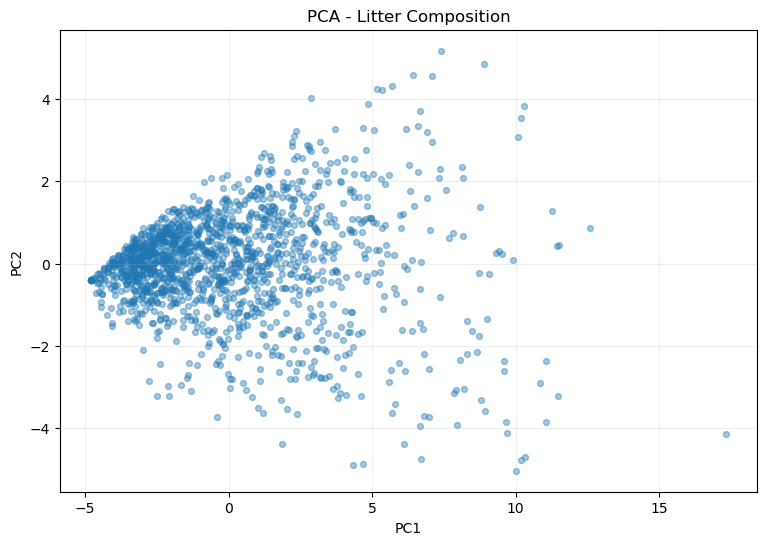


========== SILHOUETTE SCORES ==========


,Clusters,Silhouette Score
0,2,0.2888
1,3,0.1996
2,4,0.1424
3,5,0.1357
4,6,0.1112
5,7,0.0787
6,8,0.0898


In [15]:
litter_columns = df.columns[7:30].tolist()

# Prepare litter features only
X = df[litter_columns].apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median()).fillna(0)

# Check variability
print("========== DATA VARIABILITY ==========")
print("Observations:", len(X))
print("Features:", X.shape[1])
print("Unique feature combinations:", len(X.drop_duplicates()))
print("Constant features:", (X.nunique() <= 1).sum())

# Log transformation reduces influence of extreme counts
X_log = np.log1p(X.clip(lower=0))

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# PCA visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("\n========== PCA ==========")
print(
    "Explained variance by first 2 components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.4,
    s=18
)
plt.title("PCA - Litter Composition")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(alpha=0.2)
plt.show()

# Preliminary clustering quality
print("\n========== SILHOUETTE SCORES ==========")

silhouette_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "Clusters": k,
        "Silhouette Score": round(score, 4)
    })

display(pd.DataFrame(silhouette_results))